# Flood Dataset Exploration

A first look at the 12 flood images in `../data/`. Each `image_N` folder has three files:

- `image.tif`: aerial photo, 4 bands (red, green, blue, alpha)
- `dem.tif`: elevation in meters
- `label.tif`: -1 = unknown, 0 = dry, 1 = flood

Run the cells top to bottom.

## 0. Setup

In [ ]:
# pip install rasterio numpy matplotlib pandas

from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

DATA_DIR = Path("../data")
scenes = [DATA_DIR / f"image_{i}" for i in range(1, 13)]

## 1. Metadata

Size, band count, data types, and CRS for each image. `aligned` is `True` when the image, DEM, and label
have the same size, CRS, and pixel grid, so they can be stacked together as model input.

In [ ]:
rows = []
for scene in scenes:
    img = rasterio.open(scene / "image.tif")
    dem = rasterio.open(scene / "dem.tif")
    lab = rasterio.open(scene / "label.tif")

    # aligned = all three files have the same size, CRS, and pixel grid
    aligned = (
        img.shape == dem.shape == lab.shape
        and img.crs == dem.crs == lab.crs
        and img.transform == dem.transform == lab.transform
    )
    rows.append({
        "scene": scene.name,
        "bands": img.count,
        "width": img.width,
        "height": img.height,
        "img_dtype": img.dtypes[0],
        "dem_dtype": dem.dtypes[0],
        "label_dtype": lab.dtypes[0],
        "crs": str(img.crs),
        "aligned": aligned,
    })

meta = pd.DataFrame(rows)
meta

,scene,bands,width,height,img_dtype,dem_dtype,label_dtype,crs,aligned
0,image_1,4,1778,2275,uint8,float32,int16,EPSG:4326,True
1,image_2,4,2868,2151,uint8,float32,int16,EPSG:4326,True
2,image_3,4,3842,2600,uint8,float32,int16,EPSG:4326,True
3,image_4,4,2172,1550,uint8,float32,int16,EPSG:4326,True
4,image_5,4,1448,1308,uint8,float32,int16,EPSG:4326,True
5,image_6,4,1526,1417,uint8,float32,int16,EPSG:4326,True
6,image_7,4,1106,1908,uint8,float32,int16,EPSG:4326,True
7,image_8,4,3069,1692,uint8,float32,int16,EPSG:4326,True
8,image_9,4,2638,3284,uint8,float32,int16,EPSG:4326,True
9,image_10,4,1674,1953,uint8,float32,int16,EPSG:4326,True


In [ ]:
# Band-level details for one scene (descriptions / colour interpretation tell you what each band is)
with rasterio.open(scenes[0] / "image.tif") as src:
    print("Band descriptions:", src.descriptions)
    print("Color interpretation:", src.colorinterp)
    print("File tags:", src.tags())

Band descriptions: (None, None, None, None)
Color interpretation: (<ColorInterp.red: 3>, <ColorInterp.green: 4>, <ColorInterp.blue: 5>, <ColorInterp.alpha: 6>)
File tags: {'AREA_OR_POINT': 'Area'}


## 2. View each image

Photo, elevation, and label side by side. In the label: white = dry, blue = flood, red = unknown.

Things to check:
- Does the blue in the label match the water in the photo?
- Do flooded areas sit in low spots on the elevation map?
- Where are the unknown (red) areas?

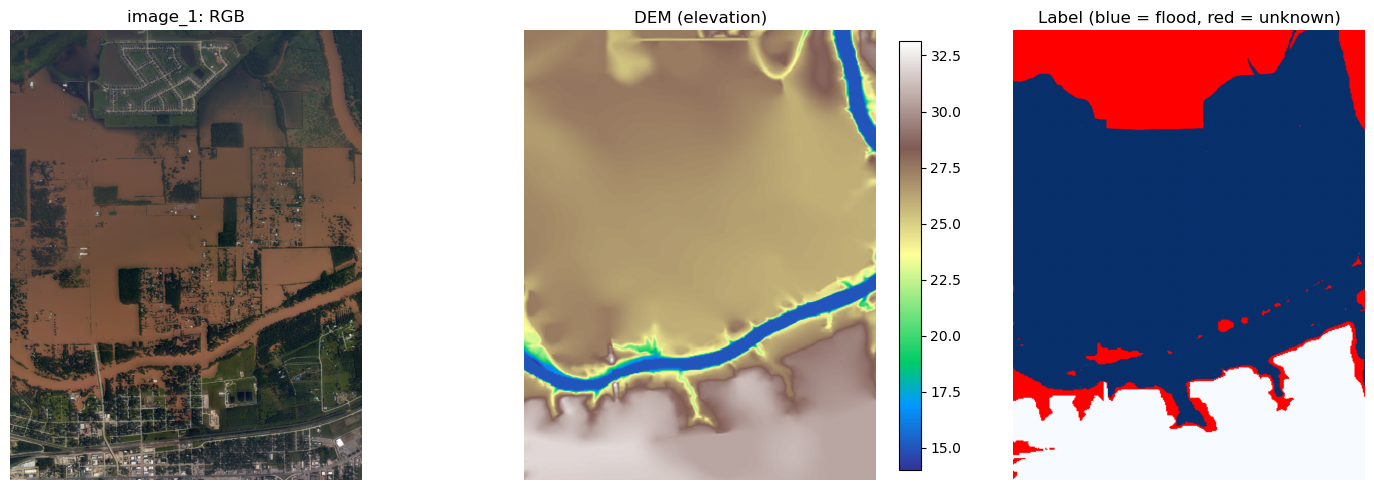

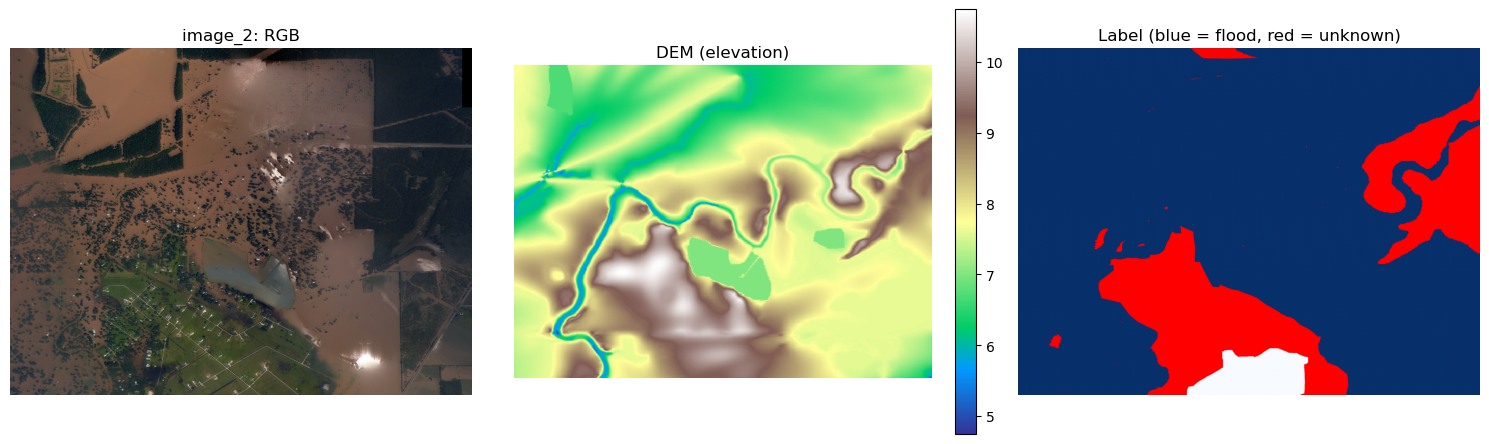

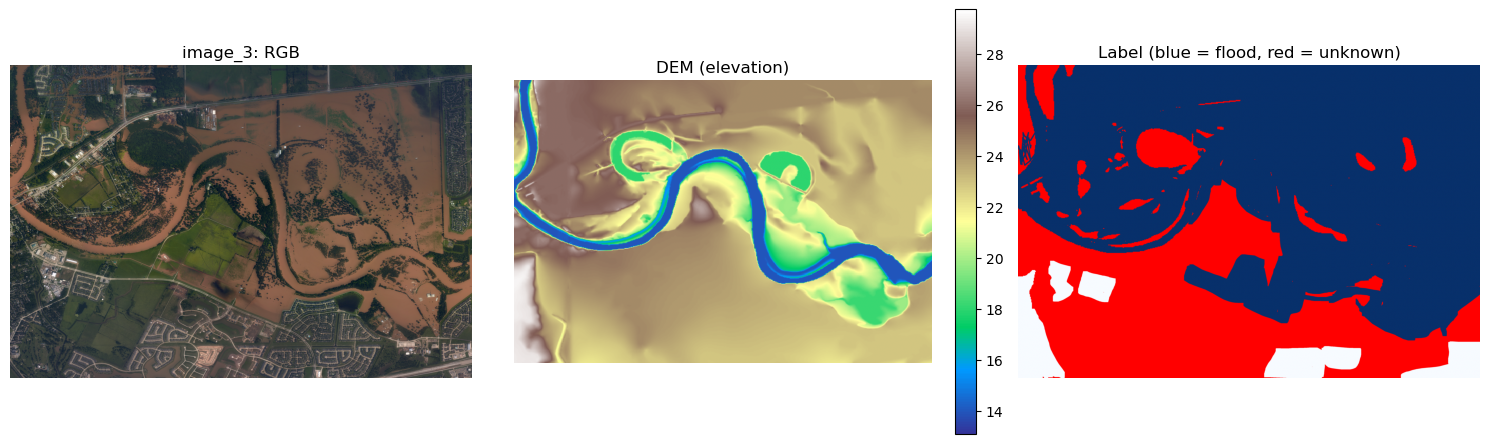

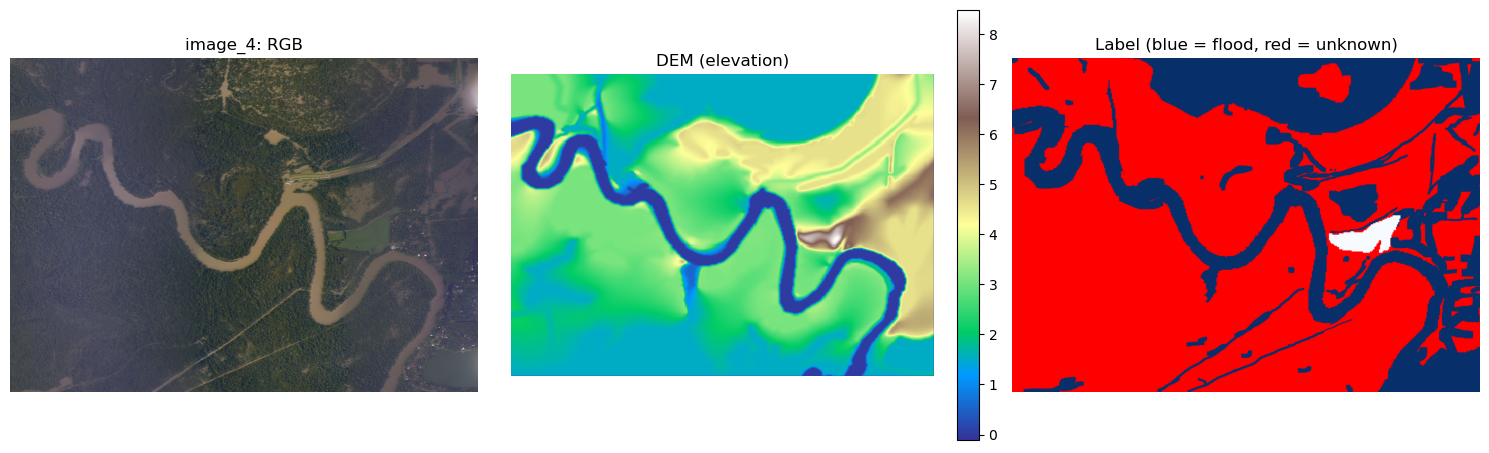

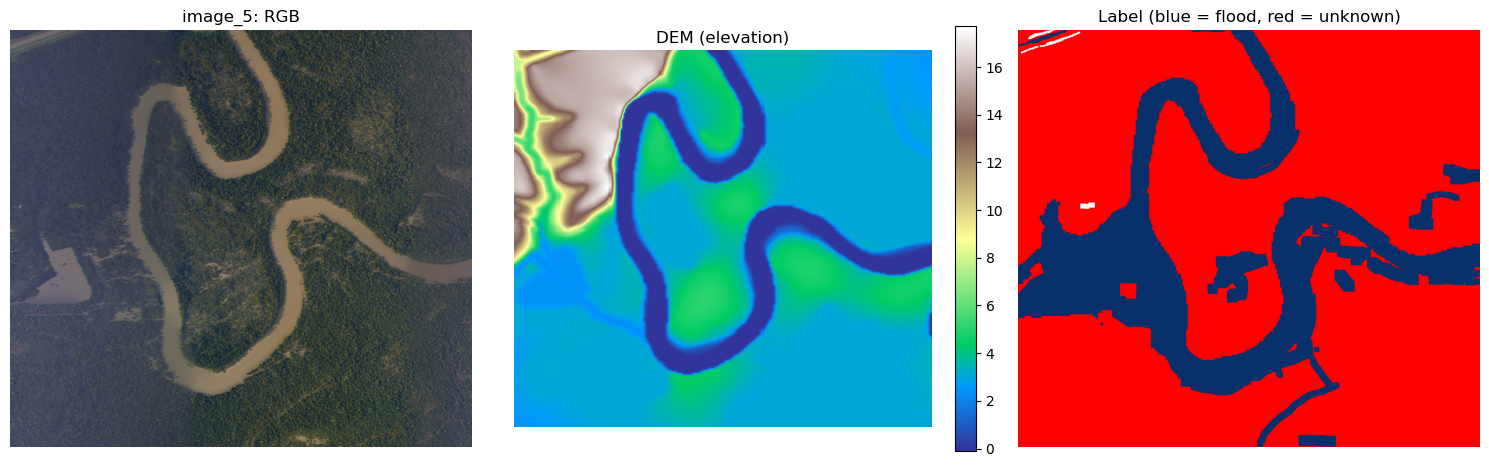

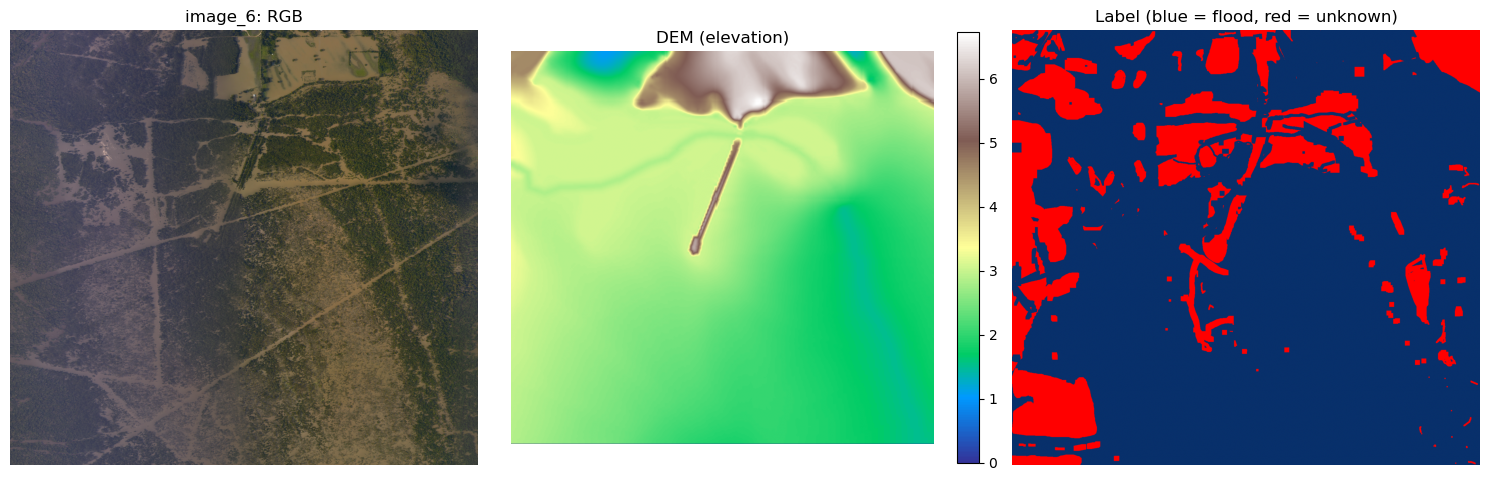

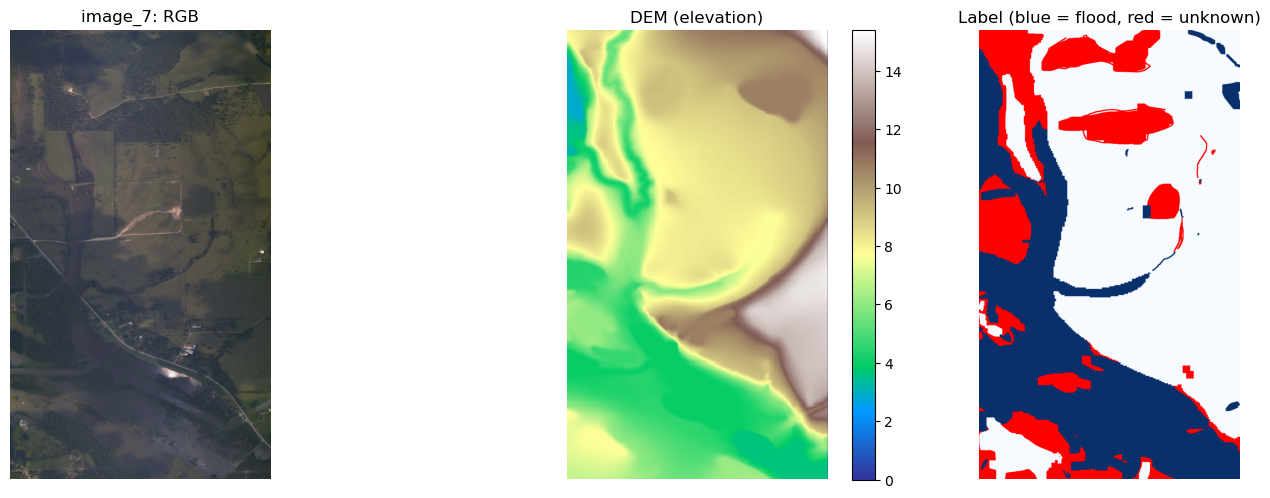

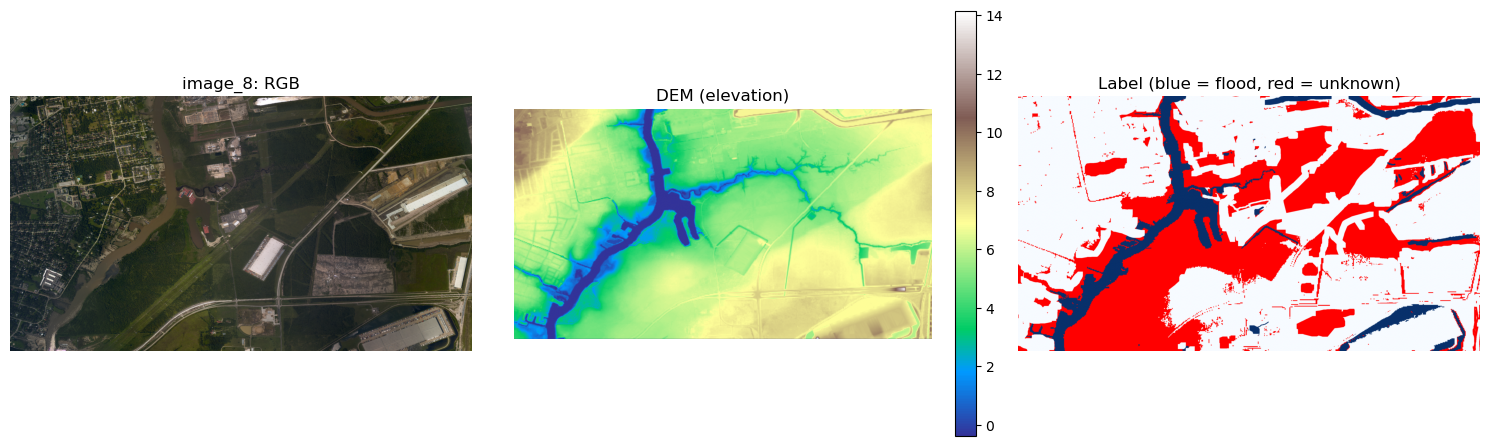

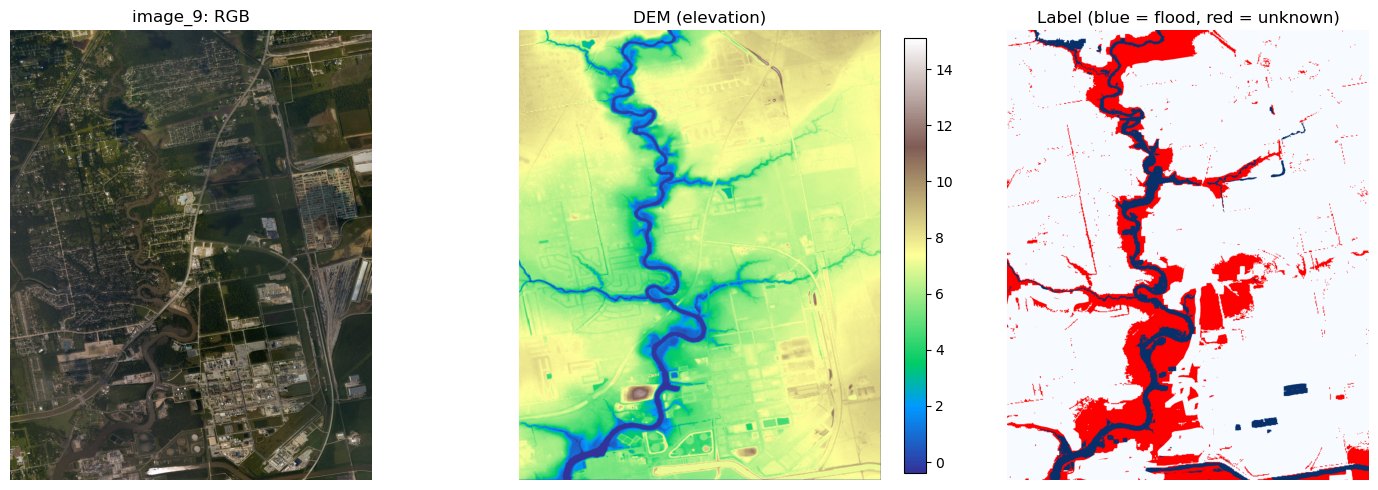

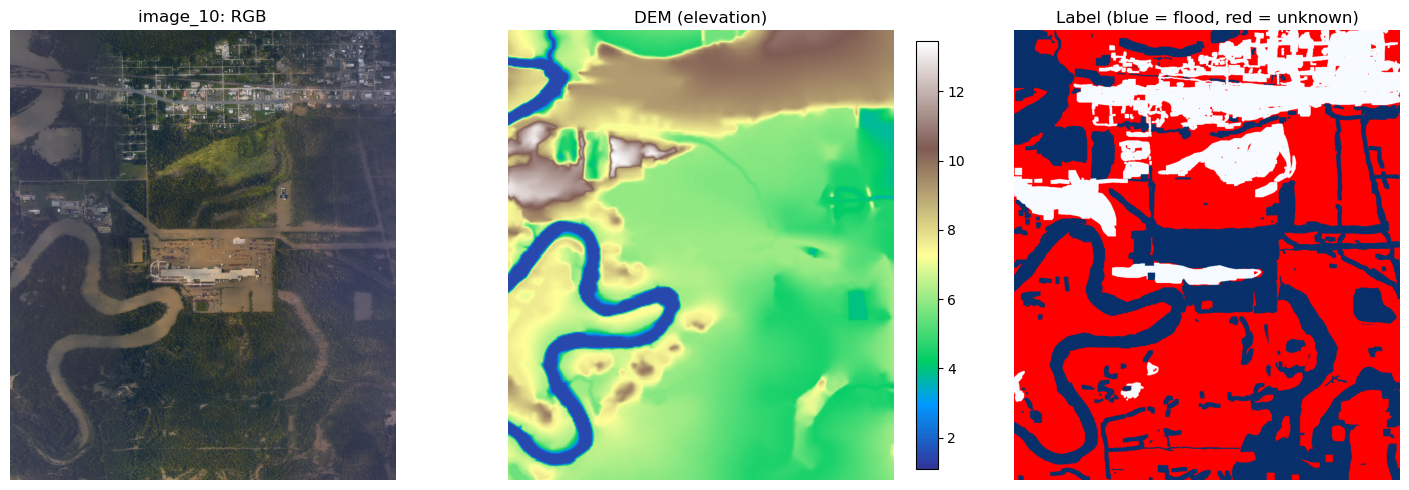

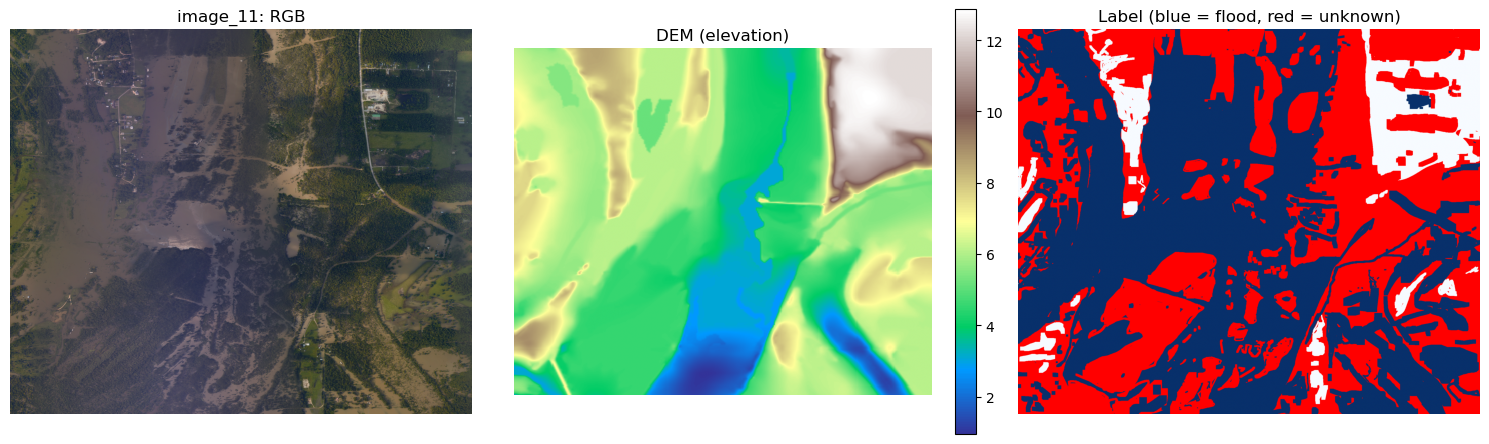

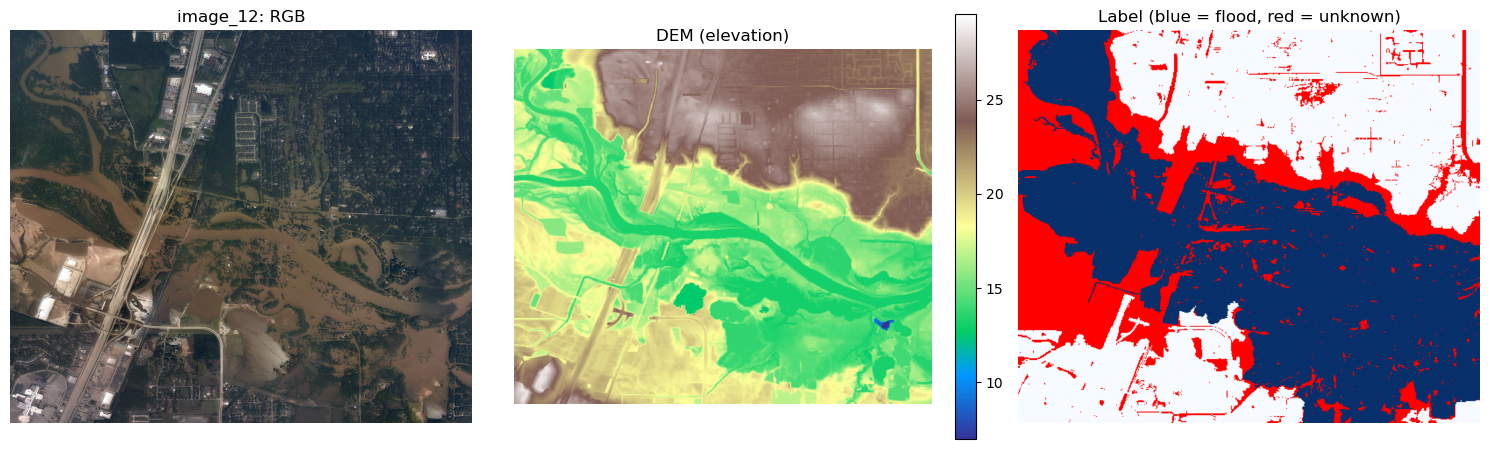

In [ ]:
def plot_scene(scene):
    rgb = rasterio.open(scene / "image.tif").read([1, 2, 3])  # skip band 4 (alpha)
    dem = rasterio.open(scene / "dem.tif").read(1)
    label = rasterio.open(scene / "label.tif").read(1)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(rgb.transpose(1, 2, 0))  # (3, H, W) -> (H, W, 3)
    axes[0].set_title(f"{scene.name}: RGB")

    im = axes[1].imshow(dem, cmap="terrain")
    axes[1].set_title("DEM (elevation)")
    fig.colorbar(im, ax=axes[1], fraction=0.046)

    label_cmap = plt.get_cmap("Blues").copy()
    label_cmap.set_bad("red")  # unknown (-1) pixels
    axes[2].imshow(np.ma.masked_equal(label, -1), cmap=label_cmap, vmin=0, vmax=1)
    axes[2].set_title("Label (blue = flood, red = unknown)")

    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

for scene in scenes:
    plot_scene(scene)

## 3. Class balance (flood vs. dry)

Pixel counts for each image. The flood percentage counts labeled pixels only (dry + flood) and leaves
unknown pixels out.

In [ ]:
rows = []
for scene in scenes:
    label = rasterio.open(scene / "label.tif").read(1)
    dry = (label == 0).sum()
    flood = (label == 1).sum()
    unknown = (label == -1).sum()
    rows.append({
        "scene": scene.name,
        "dry": dry,
        "flood": flood,
        "unknown": unknown,
        "flood_%_of_known": round(100 * flood / (dry + flood), 1),
        "unknown_%_of_total": round(100 * unknown / label.size, 1),
    })

balance = pd.DataFrame(rows)

overall = 100 * balance["flood"].sum() / (balance["dry"].sum() + balance["flood"].sum())
print(f"Overall flood %: {overall:.1f}% of known pixels")
balance

Overall flood %: 59.4% of known pixels


,scene,dry,flood,unknown,flood_%_of_known,unknown_%_of_total
0,image_1,849028,2523444,672478,74.8,16.6
1,image_2,156709,4901677,1110682,96.9,18.0
2,image_3,565531,6185611,3238058,91.6,32.4
3,image_4,30202,993561,2342837,97.0,69.6
4,image_5,2804,444658,1446522,99.4,76.4
5,image_6,0,1752644,409698,100.0,18.9
6,image_7,1095123,648304,366821,37.2,17.4
7,image_8,3156827,397169,1638752,11.2,31.6
8,image_9,6962749,447678,1252765,6.0,14.5
9,image_10,547660,949724,1771938,63.4,54.2


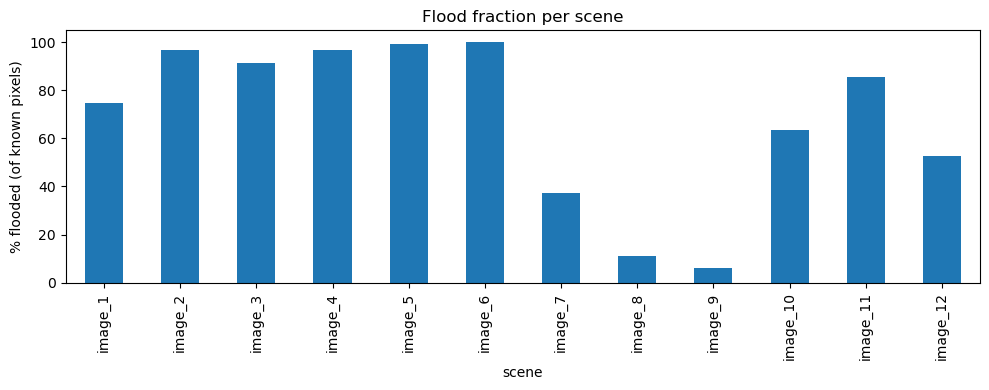

In [ ]:
ax = balance.plot.bar(x="scene", y="flood_%_of_known", legend=False, figsize=(10, 4))
ax.set_ylabel("% flooded (of known pixels)")
ax.set_title("Flood fraction per scene")
plt.tight_layout()
plt.show()